# Comparación de WAP con SAN 2014 y auditoría de WAP 2016

Este notebook realiza tres análisis independientes:

1. **WAP entrenamiento vs. test SAN 2014:** busca si alguna instancia del test aparece en el entrenamiento WAP utilizado por SAN.
2. **WAP test 2014 vs. test SAN 2014:** verifica si ambas fuentes contienen las mismas imágenes, IDs y anotaciones.
3. **WAP entrenamiento vs. WAP test 2016:** busca imágenes del test 2016 dentro del entrenamiento WAP.

El archivo WAP 2016 no incluye *ground truth* en `data/WAP`. Por ello, la tercera comparación utiliza exclusivamente identificadores e imágenes; no se infieren ni reconstruyen anotaciones.

## Evidencia utilizada

- **ID compartido:** indicio administrativo, no prueba suficiente.
- **SHA-256 de archivo:** demuestra que dos BMP son idénticos byte a byte.
- **SHA-256 de píxeles:** demuestra que dimensiones y contenido raster son idénticos, aunque la codificación cambie.
- **dHash perceptual:** genera candidatos visualmente cercanos para revisión; no demuestra identidad.
- **Ground truth compartido:** se reporta solo cuando existe y no se interpreta como la misma instancia.

Los archivos `.tar.gz` se leen directamente, sin extraer ni modificar datos.

## 1. Importaciones y configuración

In [1]:
# Librerías estándar para rutas, TAR, hashes y datos en memoria.
from pathlib import Path
from io import BytesIO
import hashlib
import json
import tarfile

# Librerías para tablas, imágenes y visualización.
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# Parámetros diagnósticos fijos.
UMBRAL_HAMMING_DHASH = 4
MAX_CANDIDATOS_POR_IMAGEN = 3
MAX_CANDIDATOS_A_VISUALIZAR = 20
MUESTRAS_COMPARACION_2014 = 8
SEMILLA = 42
REMUESTREO_LANCZOS = (
    Image.Resampling.LANCZOS
    if hasattr(Image, "Resampling")
    else Image.LANCZOS
)

pd.set_option("display.max_colwidth", 180)
pd.set_option("display.max_rows", 100)

## 2. Rutas de las fuentes

In [2]:
# Localiza la raíz mediante las cuatro fuentes necesarias.
def localizar_raiz(inicio=None):
    inicio = Path.cwd() if inicio is None else Path(inicio)
    inicio = inicio.resolve()
    for raiz in [inicio, *inicio.parents]:
        requeridos = [
            raiz / "data" / "WAP" / "off_image_train.tar.gz",
            raiz / "data" / "WAP" / "off_image_test.tar.gz",
            raiz / "data" / "WAP" / "16 (1).tar.gz",
            raiz / "data" / "Modelo1" / "2014" / "test_caption.txt",
        ]
        if all(ruta.is_file() for ruta in requeridos):
            return raiz
    raise FileNotFoundError("No se encontraron todas las fuentes requeridas.")

RAIZ = localizar_raiz()
WAP_DIR = RAIZ / "data" / "WAP"
SAN_2014_DIR = RAIZ / "data" / "Modelo1" / "2014"
RESULTADOS_DIR = RAIZ / "Cascada" / "00_analisis_exploratorio" / "resultados"

WAP_TRAIN_TAR = WAP_DIR / "off_image_train.tar.gz"
WAP_2014_TAR = WAP_DIR / "off_image_test.tar.gz"
WAP_2016_TAR = WAP_DIR / "16 (1).tar.gz"

WAP_TRAIN_CAPTION = WAP_DIR / "train_caption.txt"
WAP_2014_CAPTION = WAP_DIR / "test_caption.txt"

SAN_2014_CAPTION = SAN_2014_DIR / "test_caption.txt"
SAN_2014_IMG_DIR = SAN_2014_DIR / "14_test_images"

for ruta in [
    WAP_TRAIN_TAR, WAP_2014_TAR, WAP_2016_TAR,
    WAP_TRAIN_CAPTION, WAP_2014_CAPTION,
    SAN_2014_CAPTION, SAN_2014_IMG_DIR,
]:
    print(f"{ruta.relative_to(RAIZ)} | existe={ruta.exists()}")

data/WAP/off_image_train.tar.gz | existe=True
data/WAP/off_image_test.tar.gz | existe=True
data/WAP/16 (1).tar.gz | existe=True
data/WAP/train_caption.txt | existe=True
data/WAP/test_caption.txt | existe=True
data/Modelo1/2014/test_caption.txt | existe=True
data/Modelo1/2014/14_test_images | existe=True


## 3. Lectura de captions e inventarios de imágenes

En WAP y SAN los BMP emplean el sufijo técnico `_0.bmp`. Se retira únicamente del nombre para recuperar el ID canónico.

In [3]:
# Lee archivos caption tabulados y valida que los IDs sean únicos.
def leer_caption(ruta, particion):
    registros = []
    errores = []
    with ruta.open("r", encoding="utf-8-sig") as archivo:
        for numero_linea, linea_cruda in enumerate(archivo, start=1):
            linea = linea_cruda.rstrip("\r\n")
            if not linea.strip():
                errores.append(
                    {"particion": particion, "linea": numero_linea, "motivo": "vacía"}
                )
                continue
            if "\t" not in linea:
                errores.append(
                    {
                        "particion": particion,
                        "linea": numero_linea,
                        "motivo": "sin tabulador",
                    }
                )
                continue
            identificador, latex = linea.split("\t", maxsplit=1)
            registros.append(
                {
                    "particion": particion,
                    "orden_caption": len(registros),
                    "linea_caption": numero_linea,
                    "id": identificador.strip(),
                    "latex": latex.strip(),
                }
            )

    tabla = pd.DataFrame(registros)
    if tabla["id"].duplicated().any():
        ids = tabla.loc[tabla["id"].duplicated(keep=False), "id"].tolist()
        raise ValueError(f"IDs duplicados en {particion}: {ids[:10]}")
    return tabla, pd.DataFrame(errores)

def id_canonico(nombre):
    base = Path(nombre).stem
    return base[:-2] if base.endswith("_0") else base

# Indexa imágenes dentro de un tar sin extraerlas.
def indexar_tar(ruta_tar, particion):
    registros = []
    with tarfile.open(ruta_tar, mode="r:gz") as archivo_tar:
        for miembro in archivo_tar.getmembers():
            if miembro.isfile() and Path(miembro.name).suffix.lower() == ".bmp":
                registros.append(
                    {
                        "particion": particion,
                        "id": id_canonico(miembro.name),
                        "tipo_origen": "tar",
                        "contenedor": str(ruta_tar),
                        "referencia_imagen": miembro.name,
                        "bytes_declarados": miembro.size,
                    }
                )

    tabla = pd.DataFrame(registros)
    if tabla["id"].duplicated().any():
        ids = tabla.loc[tabla["id"].duplicated(keep=False), "id"].tolist()
        raise ValueError(f"IDs de imagen duplicados en {particion}: {ids[:10]}")
    return tabla

# Indexa las imágenes SAN ya extraídas.
def indexar_directorio(ruta_dir, particion):
    rutas = sorted(ruta_dir.glob("*.bmp"))
    tabla = pd.DataFrame(
        {
            "particion": particion,
            "id": [id_canonico(ruta.name) for ruta in rutas],
            "tipo_origen": "archivo",
            "contenedor": "",
            "referencia_imagen": [str(ruta) for ruta in rutas],
            "bytes_declarados": [ruta.stat().st_size for ruta in rutas],
        }
    )
    if tabla["id"].duplicated().any():
        ids = tabla.loc[tabla["id"].duplicated(keep=False), "id"].tolist()
        raise ValueError(f"IDs de imagen duplicados en {particion}: {ids[:10]}")
    return tabla

caption_wap_train, errores_wap_train = leer_caption(
    WAP_TRAIN_CAPTION, "wap_train"
)
caption_wap_2014, errores_wap_2014 = leer_caption(
    WAP_2014_CAPTION, "wap_2014"
)
caption_san_2014, errores_san_2014 = leer_caption(
    SAN_2014_CAPTION, "san_2014"
)

indice_wap_train = indexar_tar(WAP_TRAIN_TAR, "wap_train")
indice_wap_2014 = indexar_tar(WAP_2014_TAR, "wap_2014")
indice_wap_2016 = indexar_tar(WAP_2016_TAR, "wap_2016")
indice_san_2014 = indexar_directorio(SAN_2014_IMG_DIR, "san_2014")

## 4. Correspondencia entre captions e imágenes

In [4]:
# Resume cada fuente y verifica las particiones que sí tienen ground truth.
def resumir_fuente(nombre, imagenes, caption=None, errores=None):
    registro = {
        "fuente": nombre,
        "imagenes": len(imagenes),
        "ids_imagen_unicos": imagenes["id"].nunique(),
        "caption": len(caption) if caption is not None else pd.NA,
        "ids_caption_unicos": (
            caption["id"].nunique() if caption is not None else pd.NA
        ),
        "lineas_caption_con_error": (
            len(errores) if errores is not None else pd.NA
        ),
        "caption_sin_imagen": pd.NA,
        "imagen_sin_caption": pd.NA,
    }
    if caption is not None:
        ids_caption = set(caption["id"])
        ids_imagen = set(imagenes["id"])
        registro["caption_sin_imagen"] = len(ids_caption - ids_imagen)
        registro["imagen_sin_caption"] = len(ids_imagen - ids_caption)
    return registro

df_inventario = pd.DataFrame(
    [
        resumir_fuente(
            "wap_train", indice_wap_train,
            caption_wap_train, errores_wap_train,
        ),
        resumir_fuente(
            "wap_2014", indice_wap_2014,
            caption_wap_2014, errores_wap_2014,
        ),
        resumir_fuente("wap_2016", indice_wap_2016),
        resumir_fuente(
            "san_2014", indice_san_2014,
            caption_san_2014, errores_san_2014,
        ),
    ]
).set_index("fuente")
display(df_inventario)

columnas_validacion = [
    "lineas_caption_con_error",
    "caption_sin_imagen",
    "imagen_sin_caption",
]
valores_validacion = (
    df_inventario[columnas_validacion]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
)
if valores_validacion.to_numpy().sum() != 0:
    raise ValueError("Hay discrepancias de inventario que deben revisarse.")

,imagenes,ids_imagen_unicos,caption,ids_caption_unicos,lineas_caption_con_error,caption_sin_imagen,imagen_sin_caption
fuente,,,,,,,
wap_train,8835,8835,8835,8835,0,0,0
wap_2014,986,986,986,986,0,0,0
wap_2016,1147,1147,<NA>,<NA>,<NA>,<NA>,<NA>
san_2014,986,986,986,986,0,0,0


## 5. Cálculo de huellas

Se calculan SHA-256 del archivo, SHA-256 de píxeles y dHash. Las imágenes WAP se procesan directamente desde sus TAR.

In [5]:
# Caracteriza los bytes de una imagen una sola vez.
def caracterizar_bytes(datos):
    sha_archivo = hashlib.sha256(datos).hexdigest()

    with Image.open(BytesIO(datos)) as imagen:
        modo = imagen.mode
        ancho, alto = imagen.size
        gris_pil = imagen.convert("L")
        gris = np.asarray(gris_pil, dtype=np.uint8)
        reducida = gris_pil.resize((9, 8), REMUESTREO_LANCZOS)
        matriz_reducida = np.asarray(reducida, dtype=np.uint8)

    digest_pixeles = hashlib.sha256()
    digest_pixeles.update(np.asarray(gris.shape, dtype=np.int64).tobytes())
    digest_pixeles.update(gris.tobytes())

    comparaciones = matriz_reducida[:, 1:] > matriz_reducida[:, :-1]
    dhash = 0
    for bit in comparaciones.ravel():
        dhash = (dhash << 1) | int(bit)

    return {
        "ancho": ancho,
        "alto": alto,
        "modo": modo,
        "sha256_archivo": sha_archivo,
        "sha256_pixeles": digest_pixeles.hexdigest(),
        "dhash64": np.uint64(dhash),
    }

def caracterizar_indice_tar(indice, ruta_tar):
    registros = []
    with tarfile.open(ruta_tar, mode="r:gz") as archivo_tar:
        for _, fila in indice.iterrows():
            extraido = archivo_tar.extractfile(fila["referencia_imagen"])
            if extraido is None:
                raise FileNotFoundError(fila["referencia_imagen"])
            registros.append(
                {**fila.to_dict(), **caracterizar_bytes(extraido.read())}
            )
    return pd.DataFrame(registros)

def caracterizar_indice_archivos(indice):
    registros = []
    for _, fila in indice.iterrows():
        datos = Path(fila["referencia_imagen"]).read_bytes()
        registros.append(
            {**fila.to_dict(), **caracterizar_bytes(datos)}
        )
    return pd.DataFrame(registros)

# Esta celda es la más costosa al ejecutarse.
wap_train = caracterizar_indice_tar(indice_wap_train, WAP_TRAIN_TAR)
wap_2014 = caracterizar_indice_tar(indice_wap_2014, WAP_2014_TAR)
wap_2016 = caracterizar_indice_tar(indice_wap_2016, WAP_2016_TAR)
san_2014 = caracterizar_indice_archivos(indice_san_2014)

# Agrega ground truth solo donde está disponible.
wap_train = wap_train.merge(
    caption_wap_train[["id", "latex"]],
    on="id", how="left", validate="one_to_one",
)
wap_2014 = wap_2014.merge(
    caption_wap_2014[["id", "latex"]],
    on="id", how="left", validate="one_to_one",
)
san_2014 = san_2014.merge(
    caption_san_2014[["id", "latex"]],
    on="id", how="left", validate="one_to_one",
)

display(
    pd.DataFrame(
        {
            nombre: {
                "muestras": len(tabla),
                "hashes_archivo_unicos": tabla["sha256_archivo"].nunique(),
                "hashes_pixeles_unicos": tabla["sha256_pixeles"].nunique(),
            }
            for nombre, tabla in {
                "wap_train": wap_train,
                "wap_2014": wap_2014,
                "wap_2016": wap_2016,
                "san_2014": san_2014,
            }.items()
        }
    ).T
)

,muestras,hashes_archivo_unicos,hashes_pixeles_unicos
wap_train,8835,8793,8793
wap_2014,986,985,985
wap_2016,1147,1147,1147
san_2014,986,985,985


## 6. Funciones de comparación exacta

Los cruces por hash permiten encontrar la misma imagen aunque su ID haya cambiado.

In [6]:
# Cruza dos fuentes por una huella conservando la procedencia de cada imagen.
def cruzar_por_hash(izquierda, derecha, hash_col, etiqueta_izq, etiqueta_der):
    columnas_base = [
        "id", "tipo_origen", "contenedor", "referencia_imagen",
        "ancho", "alto", hash_col,
    ]

    columnas_izq = columnas_base + (
        ["latex"] if "latex" in izquierda.columns else []
    )
    columnas_der = columnas_base + (
        ["latex"] if "latex" in derecha.columns else []
    )

    tabla_izq = izquierda[columnas_izq].rename(
        columns={
            columna: f"{columna}_{etiqueta_izq}"
            for columna in columnas_izq
            if columna != hash_col
        }
    )
    tabla_der = derecha[columnas_der].rename(
        columns={
            columna: f"{columna}_{etiqueta_der}"
            for columna in columnas_der
            if columna != hash_col
        }
    )

    return tabla_izq.merge(
        tabla_der,
        on=hash_col,
        how="inner",
        validate="many_to_many",
    )

def resumir_cruce(nombre, izquierda, derecha, etiqueta_izq, etiqueta_der):
    ids = sorted(set(izquierda["id"]) & set(derecha["id"]))
    archivos = cruzar_por_hash(
        izquierda, derecha, "sha256_archivo", etiqueta_izq, etiqueta_der
    )
    pixeles = cruzar_por_hash(
        izquierda, derecha, "sha256_pixeles", etiqueta_izq, etiqueta_der
    )
    resumen = {
        "comparacion": nombre,
        "ids_compartidos": len(ids),
        "pares_archivo_exacto": len(archivos),
        "pares_pixeles_exactos": len(pixeles),
        "imagenes_izquierda_en_pixeles_exactos": (
            pixeles[f"id_{etiqueta_izq}"].nunique()
            if not pixeles.empty else 0
        ),
        "imagenes_derecha_en_pixeles_exactos": (
            pixeles[f"id_{etiqueta_der}"].nunique()
            if not pixeles.empty else 0
        ),
    }
    return resumen, ids, archivos, pixeles

## 7. WAP entrenamiento vs. SAN 2014

Esta comparación responde si alguna imagen del test 2014 de SAN aparece dentro del entrenamiento WAP.

In [7]:
# Busca coincidencias por ID, archivo y píxeles, independientemente del orden.
(
    resumen_train_san,
    ids_train_san,
    archivos_train_san,
    pixeles_train_san,
) = resumir_cruce(
    "wap_train vs. san_2014",
    wap_train,
    san_2014,
    "wap_train",
    "san_2014",
)

display(pd.Series(resumen_train_san, name="valor").to_frame())
display(pixeles_train_san.head(100))

,valor
comparacion,wap_train vs. san_2014
ids_compartidos,0
pares_archivo_exacto,0
pares_pixeles_exactos,0
imagenes_izquierda_en_pixeles_exactos,0
imagenes_derecha_en_pixeles_exactos,0


,id_wap_train,tipo_origen_wap_train,contenedor_wap_train,referencia_imagen_wap_train,ancho_wap_train,alto_wap_train,sha256_pixeles,latex_wap_train,id_san_2014,tipo_origen_san_2014,contenedor_san_2014,referencia_imagen_san_2014,ancho_san_2014,alto_san_2014,latex_san_2014


## 8. WAP 2014 vs. SAN 2014

Primero se alinean por ID para comparar directamente anotaciones e imágenes. Después se realiza un cruce adicional por hash para detectar posibles renombres.

In [8]:
# Alinea las 986 muestras por ID y compara sus contenidos.
comparacion_2014_por_id = wap_2014.merge(
    san_2014,
    on="id",
    how="outer",
    suffixes=("_wap", "_san"),
    indicator=True,
    validate="one_to_one",
)
comparacion_2014_por_id["archivo_igual"] = (
    comparacion_2014_por_id["sha256_archivo_wap"]
    == comparacion_2014_por_id["sha256_archivo_san"]
)
comparacion_2014_por_id["pixeles_iguales"] = (
    comparacion_2014_por_id["sha256_pixeles_wap"]
    == comparacion_2014_por_id["sha256_pixeles_san"]
)
comparacion_2014_por_id["ground_truth_igual"] = (
    comparacion_2014_por_id["latex_wap"]
    == comparacion_2014_por_id["latex_san"]
)

(
    resumen_wap14_san,
    ids_wap14_san,
    archivos_wap14_san,
    pixeles_wap14_san,
) = resumir_cruce(
    "wap_2014 vs. san_2014",
    wap_2014,
    san_2014,
    "wap_2014",
    "san_2014",
)

resumen_alineado_2014 = pd.Series(
    {
        "filas alineadas": len(comparacion_2014_por_id),
        "IDs en ambas fuentes": int(
            comparacion_2014_por_id["_merge"].eq("both").sum()
        ),
        "solo WAP": int(
            comparacion_2014_por_id["_merge"].eq("left_only").sum()
        ),
        "solo SAN": int(
            comparacion_2014_por_id["_merge"].eq("right_only").sum()
        ),
        "archivos iguales por ID": int(
            comparacion_2014_por_id["archivo_igual"].fillna(False).sum()
        ),
        "píxeles iguales por ID": int(
            comparacion_2014_por_id["pixeles_iguales"].fillna(False).sum()
        ),
        "ground truth iguales por ID": int(
            comparacion_2014_por_id["ground_truth_igual"].fillna(False).sum()
        ),
    },
    name="cantidad",
)
display(resumen_alineado_2014.to_frame())

diferencias_2014 = comparacion_2014_por_id.loc[
    comparacion_2014_por_id["_merge"].ne("both")
    | ~comparacion_2014_por_id["pixeles_iguales"].fillna(False)
    | ~comparacion_2014_por_id["ground_truth_igual"].fillna(False)
].copy()
display(diferencias_2014.head(100))

,cantidad
filas alineadas,986
IDs en ambas fuentes,986
solo WAP,0
solo SAN,0
archivos iguales por ID,986
píxeles iguales por ID,986
ground truth iguales por ID,986


,particion_wap,id,tipo_origen_wap,contenedor_wap,referencia_imagen_wap,bytes_declarados_wap,ancho_wap,alto_wap,modo_wap,sha256_archivo_wap,...,alto_san,modo_san,sha256_archivo_san,sha256_pixeles_san,dhash64_san,latex_san,_merge,archivo_igual,pixeles_iguales,ground_truth_igual


## 9. Visualización de WAP 2014 y SAN 2014

Si existen discrepancias se muestran primero. Si todo coincide, se presenta una muestra reproducible de pares para confirmar visualmente la correspondencia.

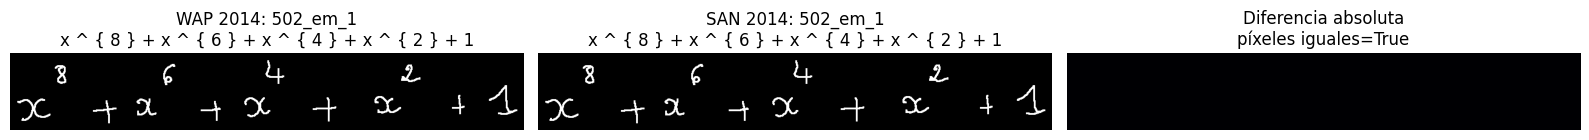

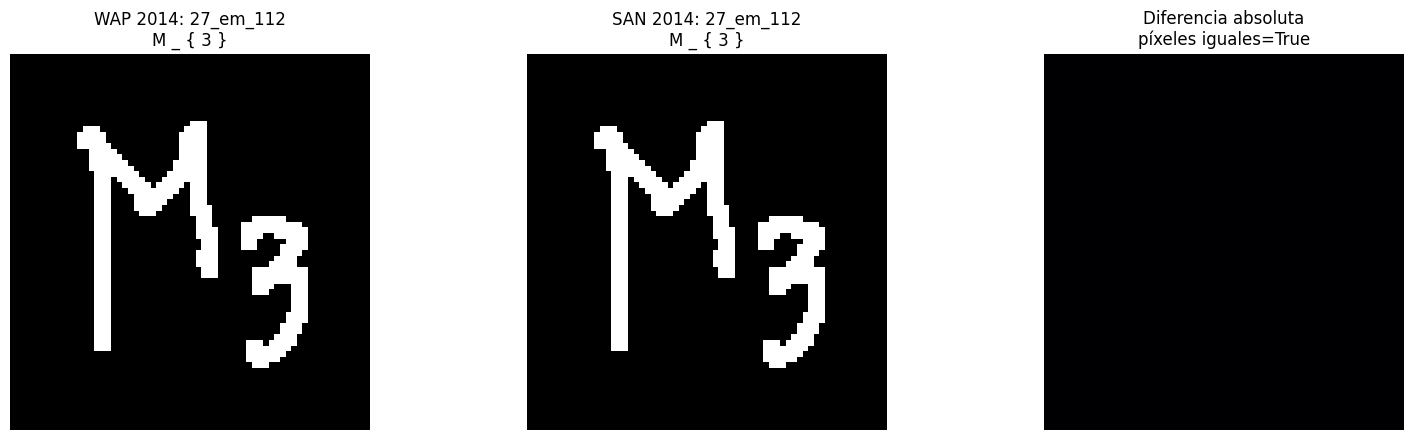

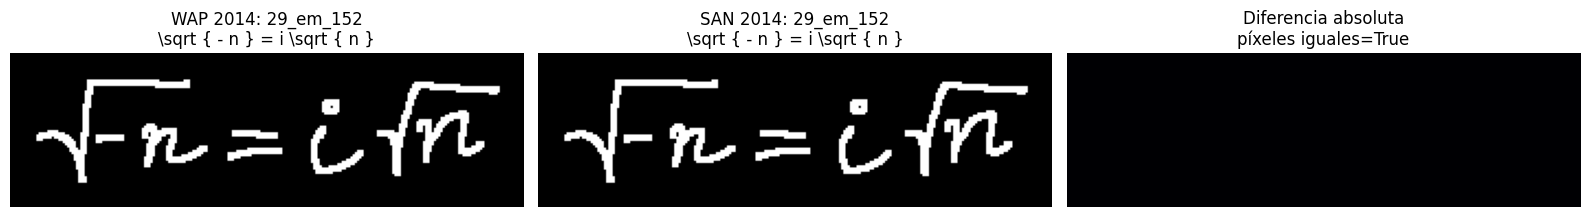

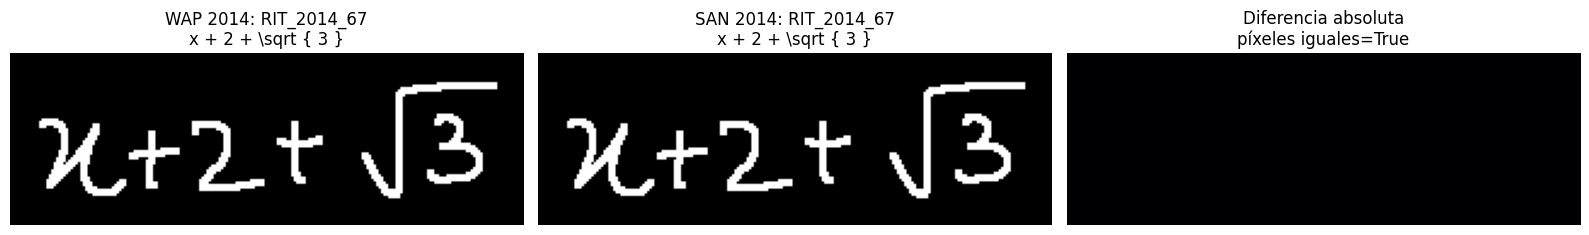

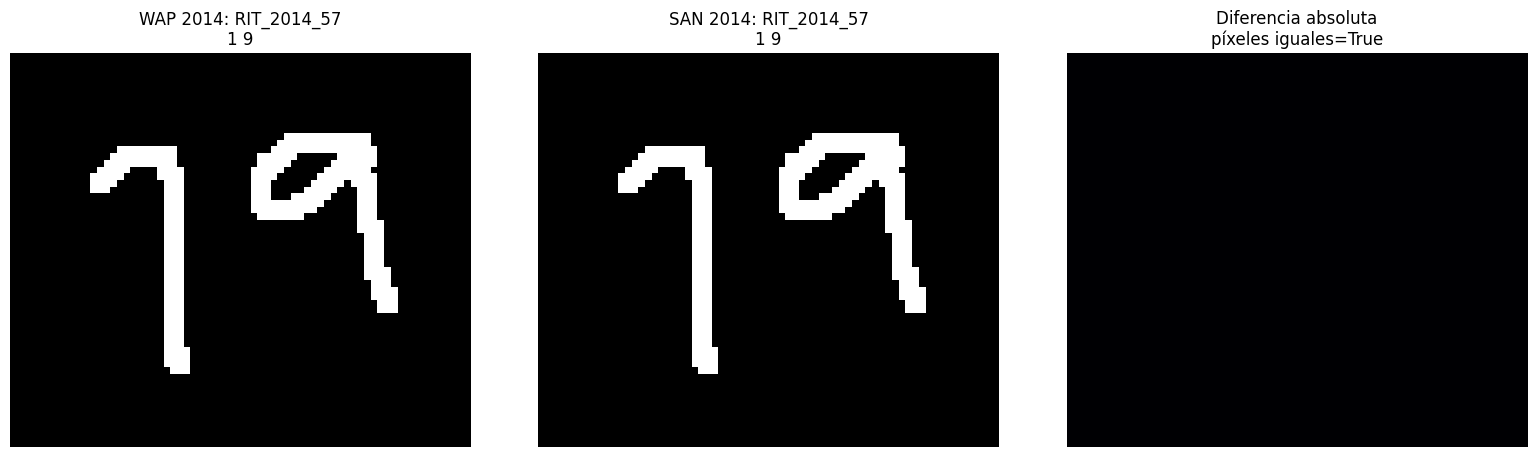

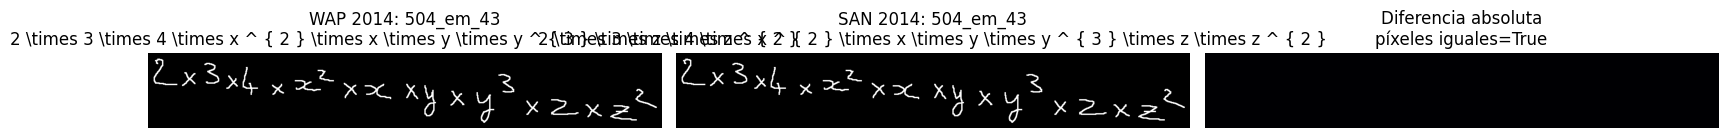

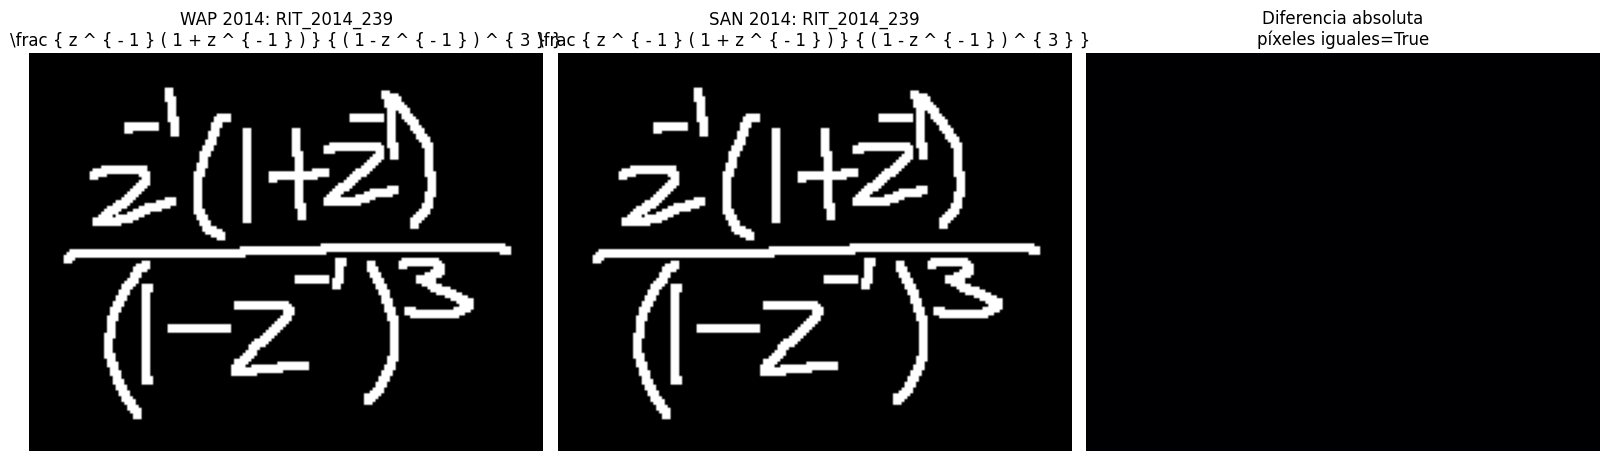

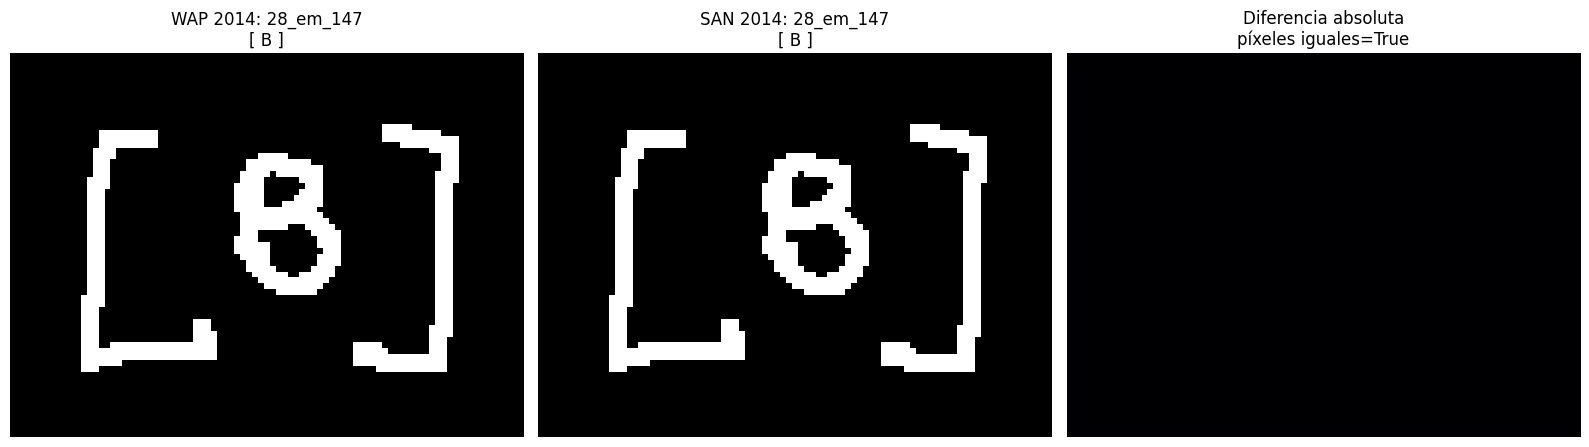

In [9]:
# Carga una imagen desde TAR o desde una ruta normal.
def cargar_imagen(tipo_origen, contenedor, referencia):
    if tipo_origen == "tar":
        with tarfile.open(contenedor, mode="r:gz") as archivo_tar:
            extraido = archivo_tar.extractfile(referencia)
            if extraido is None:
                raise FileNotFoundError(referencia)
            datos = extraido.read()
        with Image.open(BytesIO(datos)) as imagen:
            return np.asarray(imagen.convert("L"))

    with Image.open(referencia) as imagen:
        return np.asarray(imagen.convert("L"))

def mostrar_pares_2014(tabla, max_casos=MUESTRAS_COMPARACION_2014):
    if tabla.empty:
        print("No hay pares para visualizar.")
        return

    seleccion = tabla.head(max_casos)
    for _, fila in seleccion.iterrows():
        imagen_wap = cargar_imagen(
            fila["tipo_origen_wap"],
            fila["contenedor_wap"],
            fila["referencia_imagen_wap"],
        )
        imagen_san = cargar_imagen(
            fila["tipo_origen_san"],
            fila["contenedor_san"],
            fila["referencia_imagen_san"],
        )

        figura, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
        ejes[0].imshow(imagen_wap, cmap="gray", vmin=0, vmax=255)
        ejes[1].imshow(imagen_san, cmap="gray", vmin=0, vmax=255)
        ejes[0].set_title(f"WAP 2014: {fila['id']}\n{fila['latex_wap']}")
        ejes[1].set_title(f"SAN 2014: {fila['id']}\n{fila['latex_san']}")

        if imagen_wap.shape == imagen_san.shape:
            diferencia = np.abs(
                imagen_wap.astype(np.int16) - imagen_san.astype(np.int16)
            )
            ejes[2].imshow(diferencia, cmap="magma")
            ejes[2].set_title(
                f"Diferencia absoluta\n"
                f"píxeles iguales={fila['pixeles_iguales']}"
            )
        else:
            ejes[2].text(
                0.5, 0.5,
                f"Dimensiones distintas\n"
                f"WAP={imagen_wap.shape}\nSAN={imagen_san.shape}",
                ha="center", va="center",
            )
        for eje in ejes:
            eje.axis("off")
        figura.tight_layout()
        plt.show()

if diferencias_2014.empty:
    muestra_2014 = comparacion_2014_por_id.sample(
        n=min(MUESTRAS_COMPARACION_2014, len(comparacion_2014_por_id)),
        random_state=SEMILLA,
    )
    mostrar_pares_2014(muestra_2014)
else:
    mostrar_pares_2014(diferencias_2014)

## 10. WAP entrenamiento vs. WAP 2016

WAP 2016 no tiene *ground truth* disponible en esta carpeta. La comparación se limita a IDs y contenido visual.

In [10]:
# Busca coincidencias exactas sin usar ni inferir anotaciones para 2016.
(
    resumen_train_wap16,
    ids_train_wap16,
    archivos_train_wap16,
    pixeles_train_wap16,
) = resumir_cruce(
    "wap_train vs. wap_2016",
    wap_train,
    wap_2016,
    "wap_train",
    "wap_2016",
)

display(pd.Series(resumen_train_wap16, name="valor").to_frame())
display(pixeles_train_wap16.head(100))

,valor
comparacion,wap_train vs. wap_2016
ids_compartidos,0
pares_archivo_exacto,0
pares_pixeles_exactos,0
imagenes_izquierda_en_pixeles_exactos,0
imagenes_derecha_en_pixeles_exactos,0


,id_wap_train,tipo_origen_wap_train,contenedor_wap_train,referencia_imagen_wap_train,ancho_wap_train,alto_wap_train,sha256_pixeles,latex_wap_train,id_wap_2016,tipo_origen_wap_2016,contenedor_wap_2016,referencia_imagen_wap_2016,ancho_wap_2016,alto_wap_2016


## 11. Comparación auxiliar de anotaciones disponibles

Solo se comparan WAP train con SAN 2014 y WAP 2014 con SAN 2014. WAP 2016 queda expresamente fuera porque no tiene *ground truth* local.

In [11]:
# Elimina únicamente \limits para una segunda comparación documentada.
def normalizar_limits(secuencia):
    return " ".join(
        token for token in str(secuencia).split()
        if token != r"\limits"
    )

for tabla in [wap_train, wap_2014, san_2014]:
    tabla["latex_sin_limits"] = tabla["latex"].map(normalizar_limits)

resumen_ground_truth = pd.DataFrame(
    [
        {
            "comparacion": "wap_train vs. san_2014",
            "referencias_unicas_compartidas": len(
                set(wap_train["latex"]) & set(san_2014["latex"])
            ),
            "muestras_san_con_latex_en_train": int(
                san_2014["latex"].isin(set(wap_train["latex"])).sum()
            ),
            "referencias_compartidas_sin_limits": len(
                set(wap_train["latex_sin_limits"])
                & set(san_2014["latex_sin_limits"])
            ),
            "muestras_san_con_latex_sin_limits_en_train": int(
                san_2014["latex_sin_limits"].isin(
                    set(wap_train["latex_sin_limits"])
                ).sum()
            ),
        },
        {
            "comparacion": "wap_2014 vs. san_2014",
            "referencias_unicas_compartidas": len(
                set(wap_2014["latex"]) & set(san_2014["latex"])
            ),
            "muestras_san_con_latex_en_train": int(
                san_2014["latex"].isin(set(wap_2014["latex"])).sum()
            ),
            "referencias_compartidas_sin_limits": len(
                set(wap_2014["latex_sin_limits"])
                & set(san_2014["latex_sin_limits"])
            ),
            "muestras_san_con_latex_sin_limits_en_train": int(
                san_2014["latex_sin_limits"].isin(
                    set(wap_2014["latex_sin_limits"])
                ).sum()
            ),
        },
    ]
).set_index("comparacion")
display(resumen_ground_truth)

print(
    "Las coincidencias de ground truth no se interpretan como imágenes repetidas."
)

,referencias_unicas_compartidas,muestras_san_con_latex_en_train,referencias_compartidas_sin_limits,muestras_san_con_latex_sin_limits_en_train
comparacion,,,,
wap_train vs. san_2014,29,30,29,30
wap_2014 vs. san_2014,973,986,973,986


Las coincidencias de ground truth no se interpretan como imágenes repetidas.


## 12. Búsqueda perceptual para los dos cruces con entrenamiento

Se buscan candidatos cercanos en SAN 2014 y WAP 2016. Los resultados deben revisarse visualmente; dHash puede confundir expresiones distintas con formas generales parecidas.

In [12]:
# Cuenta bits diferentes entre hashes perceptuales de 64 bits.
CONTEO_BITS_BYTE = np.array(
    [bin(valor).count("1") for valor in range(256)],
    dtype=np.uint8,
)

def distancias_hamming_vector(hash_referencia, hashes):
    xor = np.bitwise_xor(hashes, np.uint64(hash_referencia))
    bytes_xor = xor.view(np.uint8).reshape(-1, 8)
    return CONTEO_BITS_BYTE[bytes_xor].sum(axis=1)

def buscar_candidatos(train, test, etiqueta_test):
    hashes_train = train["dhash64"].to_numpy(dtype=np.uint64)
    registros = []

    for _, muestra_test in test.iterrows():
        distancias = distancias_hamming_vector(
            muestra_test["dhash64"], hashes_train
        )
        indices = np.argsort(distancias)
        agregados = 0

        for indice_train in indices:
            distancia = int(distancias[indice_train])
            if distancia > UMBRAL_HAMMING_DHASH:
                break

            muestra_train = train.iloc[int(indice_train)]
            registros.append(
                {
                    "test": etiqueta_test,
                    "id_train": muestra_train["id"],
                    "id_test": muestra_test["id"],
                    "tipo_train": muestra_train["tipo_origen"],
                    "contenedor_train": muestra_train["contenedor"],
                    "referencia_train": muestra_train["referencia_imagen"],
                    "tipo_test": muestra_test["tipo_origen"],
                    "contenedor_test": muestra_test["contenedor"],
                    "referencia_test": muestra_test["referencia_imagen"],
                    "latex_train": muestra_train["latex"],
                    "latex_test": (
                        muestra_test["latex"]
                        if "latex" in muestra_test.index
                        else pd.NA
                    ),
                    "distancia_hamming": distancia,
                    "archivo_exacto": (
                        muestra_train["sha256_archivo"]
                        == muestra_test["sha256_archivo"]
                    ),
                    "pixeles_exactos": (
                        muestra_train["sha256_pixeles"]
                        == muestra_test["sha256_pixeles"]
                    ),
                    "ancho_train": muestra_train["ancho"],
                    "alto_train": muestra_train["alto"],
                    "ancho_test": muestra_test["ancho"],
                    "alto_test": muestra_test["alto"],
                }
            )
            agregados += 1
            if agregados >= MAX_CANDIDATOS_POR_IMAGEN:
                break

    return pd.DataFrame(registros)

candidatos_train_san = buscar_candidatos(
    wap_train, san_2014, "san_2014"
)
candidatos_train_wap16 = buscar_candidatos(
    wap_train, wap_2016, "wap_2016"
)

print(f"Candidatos WAP train vs. SAN 2014: {len(candidatos_train_san)}")
print(f"Candidatos WAP train vs. WAP 2016: {len(candidatos_train_wap16)}")

if not candidatos_train_san.empty:
    display(candidatos_train_san.head(100))
if not candidatos_train_wap16.empty:
    display(candidatos_train_wap16.head(100))

Candidatos WAP train vs. SAN 2014: 1
Candidatos WAP train vs. WAP 2016: 0


,test,id_train,id_test,tipo_train,contenedor_train,referencia_train,tipo_test,contenedor_test,referencia_test,latex_train,latex_test,distancia_hamming,archivo_exacto,pixeles_exactos,ancho_train,alto_train,ancho_test,alto_test
0,san_2014,200923-1251-196,507_em_75,tar,/mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/data/WAP/off_image_train.tar.gz,off_image_train/200923-1251-196_0.bmp,archivo,,/mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/data/Modelo1/2014/14_test_images/507_em_75_0.bmp,[ o ],[ b ],3,False,False,70,61,60,58


## 13. Revisión visual de candidatos perceptuales

En los candidatos WAP 2016, el panel de test muestra únicamente el ID porque no hay anotación disponible.

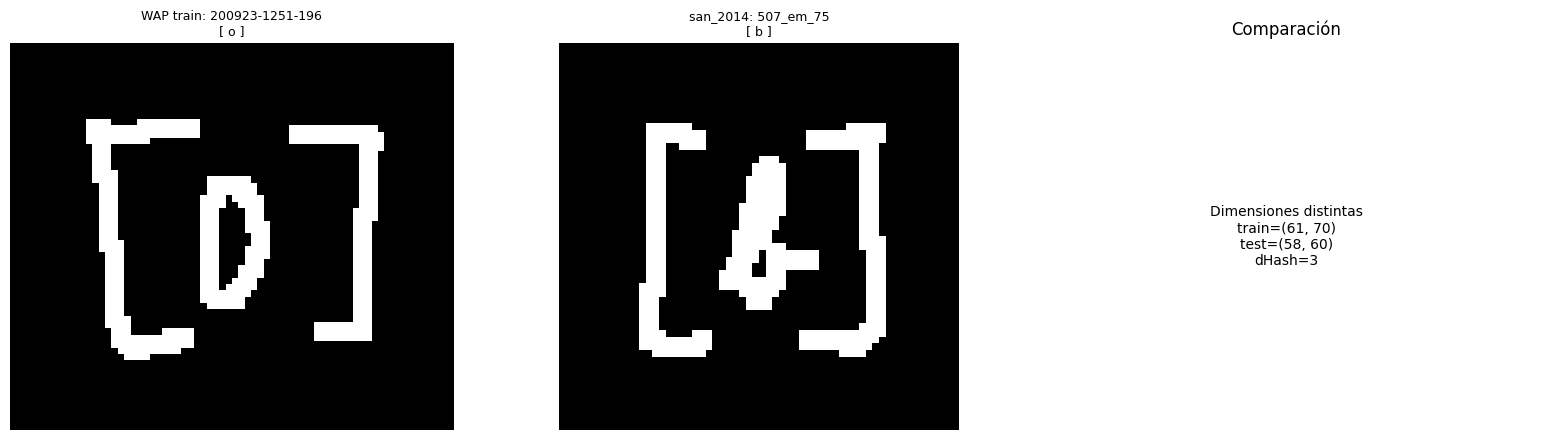

In [13]:
# Muestra candidatos sin convertir automáticamente similitud en identidad.
def mostrar_candidatos(candidatos, max_casos=MAX_CANDIDATOS_A_VISUALIZAR):
    if candidatos.empty:
        print("No hay candidatos bajo el umbral perceptual.")
        return

    seleccion = candidatos.sort_values(
        ["distancia_hamming", "test", "id_test", "id_train"]
    ).head(max_casos)

    for _, caso in seleccion.iterrows():
        imagen_train = cargar_imagen(
            caso["tipo_train"],
            caso["contenedor_train"],
            caso["referencia_train"],
        )
        imagen_test = cargar_imagen(
            caso["tipo_test"],
            caso["contenedor_test"],
            caso["referencia_test"],
        )

        figura, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
        ejes[0].imshow(imagen_train, cmap="gray", vmin=0, vmax=255)
        ejes[1].imshow(imagen_test, cmap="gray", vmin=0, vmax=255)

        ejes[0].set_title(
            f"WAP train: {caso['id_train']}\n{caso['latex_train']}",
            fontsize=9,
        )
        etiqueta_test = (
            caso["latex_test"]
            if pd.notna(caso["latex_test"])
            else "ground truth no disponible"
        )
        ejes[1].set_title(
            f"{caso['test']}: {caso['id_test']}\n{etiqueta_test}",
            fontsize=9,
        )

        if imagen_train.shape == imagen_test.shape:
            diferencia = np.abs(
                imagen_train.astype(np.int16)
                - imagen_test.astype(np.int16)
            )
            ejes[2].imshow(diferencia, cmap="magma")
            ejes[2].set_title(
                f"Diferencia absoluta\n"
                f"dHash={caso['distancia_hamming']}, "
                f"píxeles exactos={caso['pixeles_exactos']}"
            )
        else:
            ejes[2].text(
                0.5, 0.5,
                "Dimensiones distintas\n"
                f"train={imagen_train.shape}\n"
                f"test={imagen_test.shape}\n"
                f"dHash={caso['distancia_hamming']}",
                ha="center", va="center",
            )
            ejes[2].set_title("Comparación")

        for eje in ejes:
            eje.axis("off")
        figura.tight_layout()
        plt.show()

todos_candidatos = pd.concat(
    [candidatos_train_san, candidatos_train_wap16],
    ignore_index=True,
) if (
    not candidatos_train_san.empty
    or not candidatos_train_wap16.empty
) else pd.DataFrame()

mostrar_candidatos(todos_candidatos)

## 14. Tabla de revisión manual

In [14]:
# Conserva una decisión pendiente para cada candidato aproximado.
if todos_candidatos.empty:
    revision_manual = pd.DataFrame(
        columns=[
            "test", "id_train", "id_test", "distancia_hamming",
            "decision_visual", "observaciones",
        ]
    )
else:
    revision_manual = todos_candidatos[
        [
            "test", "id_train", "id_test", "distancia_hamming",
            "archivo_exacto", "pixeles_exactos",
            "latex_train", "latex_test",
        ]
    ].copy()
    revision_manual["decision_visual"] = "pendiente"
    revision_manual["observaciones"] = ""

display(revision_manual.head(100))

# Decisiones sugeridas:
# "misma instancia", "escrituras distintas", "falso positivo" o "ambiguo".

,test,id_train,id_test,distancia_hamming,archivo_exacto,pixeles_exactos,latex_train,latex_test,decision_visual,observaciones
0,san_2014,200923-1251-196,507_em_75,3,False,False,[ o ],[ b ],pendiente,


## 15. Resumen final

In [15]:
# Reúne las tres comparaciones sin atribuir ground truth a WAP 2016.
df_resumen = pd.DataFrame(
    [
        resumen_train_san,
        resumen_wap14_san,
        resumen_train_wap16,
    ]
).set_index("comparacion")

df_resumen["candidatos_perceptuales"] = [
    len(candidatos_train_san),
    pd.NA,
    len(candidatos_train_wap16),
]
display(df_resumen)

print(
    "La conclusión sobre solapamientos exactos se basa en ID, archivo y píxeles. "
    "Los candidatos perceptuales requieren revisión manual."
)

,ids_compartidos,pares_archivo_exacto,pares_pixeles_exactos,imagenes_izquierda_en_pixeles_exactos,imagenes_derecha_en_pixeles_exactos,candidatos_perceptuales
comparacion,,,,,,
wap_train vs. san_2014,0,0,0,0,0,1
wap_2014 vs. san_2014,986,988,988,986,986,<NA>
wap_train vs. wap_2016,0,0,0,0,0,0


La conclusión sobre solapamientos exactos se basa en ID, archivo y píxeles. Los candidatos perceptuales requieren revisión manual.


## 16. Exportación de resultados

In [16]:
# Guarda tablas trazables únicamente cuando el usuario ejecute esta celda.
RESULTADOS_DIR.mkdir(parents=True, exist_ok=True)

df_inventario.to_csv(
    RESULTADOS_DIR / "comparacion_wap_san_inventario.csv"
)
df_resumen.to_csv(
    RESULTADOS_DIR / "comparacion_wap_san_resumen.csv"
)
comparacion_2014_por_id.to_csv(
    RESULTADOS_DIR / "comparacion_wap_2014_vs_san_2014_por_id.csv",
    index=False,
)
pixeles_train_san.to_csv(
    RESULTADOS_DIR / "solapamientos_wap_train_vs_san_2014_pixeles.csv",
    index=False,
)
pixeles_train_wap16.to_csv(
    RESULTADOS_DIR / "solapamientos_wap_train_vs_wap_2016_pixeles.csv",
    index=False,
)
resumen_ground_truth.to_csv(
    RESULTADOS_DIR / "comparacion_wap_san_ground_truth.csv"
)
revision_manual.to_csv(
    RESULTADOS_DIR / "comparacion_wap_san_revision_manual.csv",
    index=False,
)
candidatos_train_san.to_csv(
    RESULTADOS_DIR / "candidatos_wap_train_vs_san_2014.csv",
    index=False,
)
candidatos_train_wap16.to_csv(
    RESULTADOS_DIR / "candidatos_wap_train_vs_wap_2016.csv",
    index=False,
)

resumen_json = {
    "comparaciones": [
        "wap_train vs. san_2014",
        "wap_2014 vs. san_2014",
        "wap_train vs. wap_2016",
    ],
    "wap_2016_ground_truth_disponible": False,
    "parametros_diagnosticos": {
        "umbral_hamming_dhash": UMBRAL_HAMMING_DHASH,
        "max_candidatos_por_imagen": MAX_CANDIDATOS_POR_IMAGEN,
        "semilla": SEMILLA,
    },
    "interpretacion": (
        "Los hashes exactos demuestran identidad. "
        "dHash solo genera candidatos para revisión."
    ),
}

with (
    RESULTADOS_DIR / "comparacion_wap_san_resumen.json"
).open("w", encoding="utf-8") as archivo:
    json.dump(resumen_json, archivo, ensure_ascii=False, indent=2)

print(f"Resultados guardados en: {RESULTADOS_DIR}")

Resultados guardados en: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/00_analisis_exploratorio/resultados


## Guía de interpretación

- Si WAP train y SAN 2014 comparten píxeles exactos, existe una instancia del test dentro del entrenamiento WAP.
- Si WAP 2014 y SAN 2014 coinciden por ID, píxeles y anotación, representan la misma partición preparada para ambos repositorios.
- Si WAP train y WAP 2016 comparten píxeles exactos, existe una instancia del test 2016 dentro del entrenamiento, aunque no haya *ground truth* disponible.
- Una coincidencia de dHash no basta: debe verificarse visualmente.
- Una anotación repetida no prueba reutilización de imagen.
- La auditoría no modifica archivos ni autoriza excluir muestras automáticamente.